In [1]:
import osgeo
import rasterio
import rasterio.plot
import rioxarray
import xarray as xr
from rasterio.warp import transform_bounds
from rasterio.windows import from_bounds
from rasterio.windows import Window
from matplotlib import pyplot
import numpy as np
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import netCDF4
import h5netcdf
import dask
import rasterio.features as features

## Open data

In [2]:
path_tree_cover_density = 'C:/Users/minttu/Documents/Tree_cover/TCD2010_0.05deg.tif'

In [3]:
path_LC_Hansen = 'C:/Users/minttu/Documents/LC_300m_data/ESACCI-LC-L4-LCCS-Map-300m-P1Y-2000-Resample_0.05deg.tif'

In [4]:
TCD = rioxarray.open_rasterio(path_tree_cover_density)

In [5]:
LCHansen2000 = rioxarray.open_rasterio(path_LC_Hansen)

## Plot tree cover density and land cover

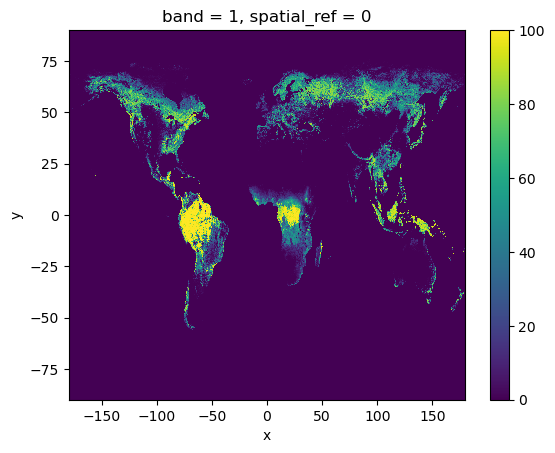

In [6]:
TCD.plot()

## Create LCD layer

All selected classes of the LC2000 data set are first extracted as binary masks per class, some of the land cover classes are area weighted depending on the percentage of tree cover as provided by the Land Cover CCI. 

In [43]:
LCD = LCHansen2000.where(LCHansen2000 != 30, 0.5)
LCD = LCD.where(LCD != 110, 0.5)
LCD = LCD.where(LCD != 150, 0.15)

In [44]:
values_to_replace = [40, 50, 60, 61, 62, 70, 71, 72, 80, 81, 82, 90, 100, 120, 121, 122, 160, 170, 180]
mask = LCD.isin(values_to_replace)
LCD = LCD.where(~mask, 1)

In [45]:
values_to_replace = [10, 11, 12, 20, 130, 140, 151, 152, 153, 190, 201, 202, 200, 210, 220]
mask = LCD.isin(values_to_replace)
LCD = LCD.where(~mask, False)

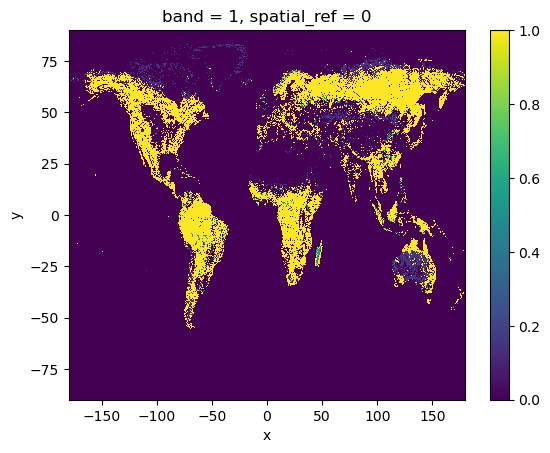

In [9]:
LCD.plot()

In [46]:
print(np.unique(LCHansen2000.values[~np.isnan(LCHansen2000.values)]))

[ 10.  11.  12.  20.  30.  40.  50.  60.  61.  62.  70.  71.  72.  80.
  81.  90. 100. 110. 120. 121. 122. 130. 140. 150. 151. 152. 153. 160.
 170. 180. 190. 200. 201. 202. 210. 220.]


In [47]:
print(np.unique(LCD.values[~np.isnan(LCD.values)]))

[0.   0.15 0.5  1.  ]


## Calculate transmissivity

In [48]:
e = 2.718281828459045235360287471352

In [54]:
t2 = 0.08 * e ** ((1-(TCD*LCD))*2.52572864)

In [50]:
# getting the original colormap using cm.get_cmap() function
orig_map=pyplot.cm.get_cmap('Greens')

# reversing the original colormap using reversed() function
reversed_map = orig_map.reversed()

C:\Users\minttu\AppData\Local\Temp\ipykernel_10432\3636168311.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  orig_map=pyplot.cm.get_cmap('Greens')


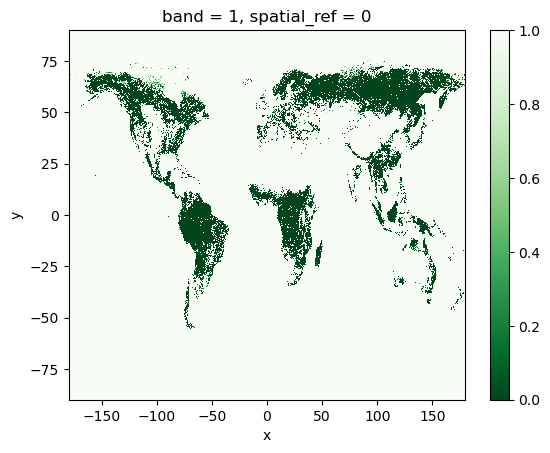

In [55]:
t2.plot(cmap=reversed_map)

In [56]:
print(np.unique(t2.values[~np.isnan(t2.values)]))

[0.0000000e+00 1.4012985e-45 4.2038954e-45 1.4012985e-44 4.7644148e-44
 1.6675452e-43 5.8714406e-43 2.0767243e-42 7.3428040e-42 2.5961857e-41
 9.1787852e-41 3.2451830e-40 1.1473453e-39 4.0564732e-39 1.4341889e-38
 5.0706176e-38 1.7927319e-37 6.3382568e-37 2.2409093e-36 7.9228018e-36
 2.8011301e-35 9.9035537e-35 3.5014308e-34 1.2379413e-33 4.3767784e-33
 1.5474228e-32 5.4709594e-32 1.9342888e-31 6.8387351e-31 2.4178550e-30
 8.5483980e-30 3.0223116e-29 1.0685513e-28 3.7778948e-28 1.3356860e-27
 4.7223752e-27 1.6696096e-26 5.9029549e-26 2.0870151e-25 7.3787037e-25
 2.6087626e-24 9.2233925e-24 3.2609579e-23 1.1529213e-22 4.0761877e-22
 1.4411537e-21 5.0952415e-21 1.8014378e-20 6.3690613e-20 2.2518004e-19
 7.9613073e-19 2.8147544e-18 9.9516478e-18 3.5184346e-17 1.2439577e-16
 2.3390053e-16 4.3980494e-16 7.2885687e-16 1.0645783e-15 1.5549435e-15
 4.8453368e-15 5.4975593e-15 1.5098484e-14 1.9436821e-14 2.2053094e-14
 6.8719458e-14 1.0037276e-13 1.4660612e-13 2.1413570e-13 2.4296014e-13
 3.127

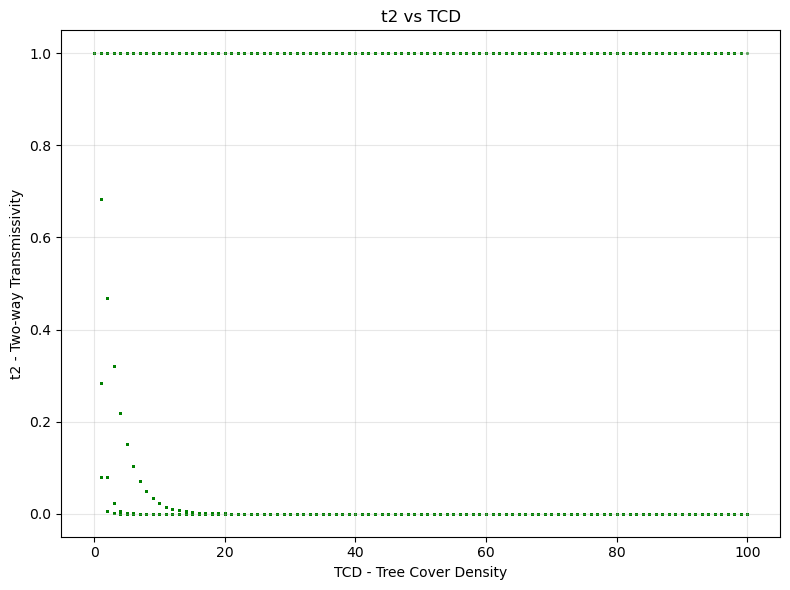

In [57]:
pyplot.figure(figsize=(8, 6))
pyplot.scatter(
    TCD.values.flatten(),
    t2.values.flatten(),
    alpha=0.1, s=1, color='green'
)
pyplot.xlabel('TCD - Tree Cover Density')
pyplot.ylabel('t2 - Two-way Transmissivity')
pyplot.title('t2 vs TCD')
pyplot.grid(True, alpha=0.3)
pyplot.tight_layout()
pyplot.show()

## Plot the reflectance in Kemijoki